# Giai đoạn 2: Tiền xử lý & Làm sạch Dữ liệu (Data Preprocessing & Sanitization Pipeline)
**Dự án:** Phân tích Dữ liệu Thương mại Điện tử Olist (Brazil, 2016–2018)

Notebook này tài liệu hóa chi tiết toàn bộ các giai đoạn làm sạch dữ liệu chuẩn bị cho phân tích chuyên sâu và Machine Learning theo đúng **4 trụ cột kỹ thuật bắt buộc**:
1. **Handling Missing Values:** Định lượng tỷ lệ % missing của từng cột và áp dụng các phương pháp kỹ thuật (row deletion, median substitution, holding constant with business justification).
2. **Outlier Detection & Treatment:** Sử dụng khung toán học IQR và biểu đồ Boxplots trực quan để cô lập dị biệt; giải thích rõ chiến lược xử lý (Preservation, Removal, Capping).
3. **Data Type Conversions:** Chuẩn hóa các cột sai định dạng (chuỗi văn bản thành `datetime64[ns]`, mã bưu chính thành chuỗi 5 ký tự `zfill(5)`, sửa lỗi chính tả tên cột).
4. **Feature Engineering & Categorical Encoding:**
   - Trích xuất các đặc trưng dự báo mới (`delivery_duration`, `delay_days`, `is_delayed`, `freight_ratio`, v.v.) và lập bảng danh mục đặc trưng.
   - Chuyển đổi các yếu tố phân loại thành biến số (One-Hot Encoding) để sẵn sàng cho mô hình học máy downstream.
5. **Validation Audit & Export:** Kiểm chứng 14 tiêu chuẩn toàn vẹn, lập nhật ký biến động số dòng và xuất dữ liệu sạch ra `data/processed/`.


## 0. Cấu hình Môi trường & Nạp 9 Bảng Dữ Liệu Gốc (Environment Setup & Data Loading)
- Gom toàn bộ thư viện cần thiết theo chuẩn PEP 8.
- Cố định seed ngẫu nhiên `RANDOM_STATE = 42` để bảo đảm tính tái lập (Reproducibility).
- Tự động nhận diện thư mục dự án và khởi tạo lớp `PreprocessingLogger` ghi vết số dòng qua từng bước.


In [16]:
import os
import warnings
from pathlib import Path
from typing import Dict, List, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 1. Cấu hình cảnh báo & Seed ngẫu nhiên
warnings.filterwarnings('ignore')
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# 2. Cấu hình hiển thị chuẩn
pd.set_option('display.max_columns', 60)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', lambda x: f'{x:.2f}')
sns.set_theme(style='whitegrid', palette='muted')

# 3. Quản lý đường dẫn dự án an toàn và linh hoạt
def find_project_root(start_dir: Path) -> Path:
    candidates = [
        start_dir,
        *start_dir.parents,
        Path("C:/ADY291c-AI2107-Group2"),
        Path.cwd(),
        *Path.cwd().parents
    ]
    for candidate in candidates:
        if (candidate / 'data' / 'raw').is_dir():
            return candidate
    raise FileNotFoundError(f"Không tìm thấy thư mục data/raw từ: {start_dir}")

BASE_DIR = find_project_root(Path.cwd().resolve())
RAW_DATA_DIR = BASE_DIR / 'data' / 'raw'
PROCESSED_DATA_DIR = BASE_DIR / 'data' / 'processed'
PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)

# 4. Hằng số ranh giới địa lý Brazil
BRAZIL_LAT_BOUNDS: Tuple[float, float] = (-33.75, 5.27)
BRAZIL_LNG_BOUNDS: Tuple[float, float] = (-73.99, -34.79)

# 5. Lớp nhật ký theo dõi biến động số dòng
class PreprocessingLogger:
    def __init__(self):
        self.logs: List[Dict[str, any]] = []
        
    def record(self, step_name: str, table_name: str, before_count: int, after_count: int, description: str):
        removed_count = before_count - after_count
        pct_retained = (after_count / before_count * 100) if before_count > 0 else 100.0
        self.logs.append({
            'Giai Đoạn': step_name,
            'Bảng Dữ Liệu': table_name,
            'Số Dòng Trước': f"{before_count:,}",
            'Số Dòng Sau': f"{after_count:,}",
            'Số Dòng Giảm': f"{removed_count:,}",
            'Tỷ Lệ Giữ Lại (%)': f"{pct_retained:.2f}%",
            'Chiến Lược & Ghi Chú': description
        })
        
    def get_dataframe(self) -> pd.DataFrame:
        return pd.DataFrame(self.logs)

pipeline_logger = PreprocessingLogger()

# 6. Hàm nạp 9 bảng CSV gốc
def load_raw_data(data_dir: Path) -> Dict[str, pd.DataFrame]:
    file_mapping = {
        'orders': 'olist_orders_dataset.csv',
        'order_items': 'olist_order_items_dataset.csv',
        'payments': 'olist_order_payments_dataset.csv',
        'reviews': 'olist_order_reviews_dataset.csv',
        'products': 'olist_products_dataset.csv',
        'customers': 'olist_customers_dataset.csv',
        'sellers': 'olist_sellers_dataset.csv',
        'geolocation': 'olist_geolocation_dataset.csv',
        'category_translation': 'product_category_name_translation.csv'
    }
    
    zip_cols = {
        'customers': {'customer_zip_code_prefix': str},
        'sellers': {'seller_zip_code_prefix': str},
        'geolocation': {'geolocation_zip_code_prefix': str}
    }
    
    loaded_dfs = {}
    for key, filename in file_mapping.items():
        filepath = data_dir / filename
        if not filepath.is_file():
            raise FileNotFoundError(f"Không tìm thấy file: {filepath.name}")
        dtype_param = zip_cols.get(key, None)
        loaded_dfs[key] = pd.read_csv(filepath, dtype=dtype_param)
        
    return loaded_dfs

dfs = load_raw_data(RAW_DATA_DIR)
print(f"Đã nạp thành công 9 bảng dữ liệu gốc từ: {RAW_DATA_DIR}")


Đã nạp thành công 9 bảng dữ liệu gốc từ: C:\ADY291c-AI2107-Group2\data\raw


## 1. Data Type Conversions (Chuyển Đổi Kiểu Dữ Liệu & Chuẩn Hóa Định Dạng)
Chuyển đổi kiểu dữ liệu là bước nền tảng để bảo đảm các phép tính toán thời gian, gom nhóm và lọc dữ liệu diễn ra chính xác:
- **Chuẩn hóa Datetime:** Ép toàn bộ các cột thời gian dạng chuỗi (`object`) sang định dạng `datetime64[ns]` bằng `pd.to_datetime(..., errors='coerce')`.
- **Chuẩn hóa Mã Bưu Chính (ZIP Code):** Mã bưu chính Brazil có 5 chữ số; nếu lưu dưới dạng số nguyên (`int64`), các mã có số 0 ở đầu (ví dụ `01001` ở São Paulo) sẽ bị mất thành `1001`. Do đó, cần ép kiểu chuỗi ký tự và định dạng đủ 5 chữ số bằng `.str.zfill(5)`.
- **Sửa Lỗi Chính Tả Tên Cột:** Bảng `products` có 2 cột sai chính tả tiếng Anh (`product_name_lenght` và `product_description_lenght`), cần chuẩn hóa thành `..._length`.
- **Chuẩn Hóa Chuỗi Văn Bản:** Đưa tên thành phố về chữ thường (`lower()`) và tên bang về chữ hoa (`upper()`) để tránh phân mảnh dữ liệu phân loại.


In [17]:
# 1. Ép kiểu datetime cho các cột mốc thời gian
datetime_cols_map = {
    'orders': [
        'order_purchase_timestamp', 'order_approved_at',
        'order_delivered_carrier_date', 'order_delivered_customer_date',
        'order_estimated_delivery_date','order_approved_at'],
    'order_items': ['shipping_limit_date'],
    'reviews': ['review_creation_date', 'review_answer_timestamp']
}
for table_name, cols in datetime_cols_map.items():
    for col in cols:
        dfs[table_name][col] = pd.to_datetime(dfs[table_name][col], errors='coerce')

# 2. Chuẩn hóa mã ZIP code thành chuỗi 5 chữ số zfill(5) và chuẩn hóa văn bản
for tbl, col, city_col, state_col in [
    ('customers', 'customer_zip_code_prefix', 'customer_city', 'customer_state'),
    ('sellers', 'seller_zip_code_prefix', 'seller_city', 'seller_state')
]:
    dfs[tbl][col] = dfs[tbl][col].astype(str).str.strip().str.zfill(5)
    dfs[tbl][city_col] = dfs[tbl][city_col].astype(str).str.strip().str.lower()
    dfs[tbl][state_col] = dfs[tbl][state_col].astype(str).str.strip().str.upper()

dfs['geolocation']['geolocation_zip_code_prefix'] = (
    dfs['geolocation']['geolocation_zip_code_prefix'].astype(str).str.strip().str.zfill(5)
)

# 3. Sửa lỗi chính tả tên cột trong bảng products
dfs['products'] = dfs['products'].rename(columns={
    'product_name_lenght': 'product_name_length',
    'product_description_lenght': 'product_description_length'
})

# 4. Hiển thị bảng đối chiếu kiểu dữ liệu sau chuẩn hóa
dtype_conversion_summary = pd.DataFrame([
    {'Bảng Dữ Liệu': 'orders', 'Cột': '5 cột mốc thời gian', 'Kiểu Dữ Liệu Gốc': 'object (chuỗi text)', 'Kiểu Sau Chuẩn Hóa': 'datetime64[ns]', 'Mục Đích': 'Tính toán thời gian giao hàng và độ trễ'},
    {'Bảng Dữ Liệu': 'order_items', 'Cột': 'shipping_limit_date', 'Kiểu Dữ Liệu Gốc': 'object (chuỗi text)', 'Kiểu Sau Chuẩn Hóa': 'datetime64[ns]', 'Mục Đích': 'Xác định hạn chót gửi hàng của người bán'},
    {'Bảng Dữ Liệu': 'reviews', 'Cột': 'review_creation/answer_date', 'Kiểu Dữ Liệu Gốc': 'object (chuỗi text)', 'Kiểu Sau Chuẩn Hóa': 'datetime64[ns]', 'Mục Đích': 'Xác định thời gian phản hồi của khách hàng'},
    {'Bảng Dữ Liệu': 'customers/sellers/geo', 'Cột': '*_zip_code_prefix', 'Kiểu Dữ Liệu Gốc': 'int64 / chuỗi thiếu số 0', 'Kiểu Sau Chuẩn Hóa': 'object (str đủ 5 ký tự)', 'Mục Đích': 'Bảo toàn mã bưu chính có số 0 ở đầu (01001)'},
    {'Bảng Dữ Liệu': 'products', 'Cột': 'product_*_length', 'Kiểu Dữ Liệu Gốc': 'lenght (sai chính tả)', 'Kiểu Sau Chuẩn Hóa': 'length (chuẩn tiếng Anh)', 'Mục Đích': 'Chuẩn hóa định danh thuộc tính'}
])

print("Hoàn tất chuyển đổi kiểu dữ liệu & chuẩn hóa định dạng.")
display(dtype_conversion_summary)


Hoàn tất chuyển đổi kiểu dữ liệu & chuẩn hóa định dạng.


,Bảng Dữ Liệu,Cột,Kiểu Dữ Liệu Gốc,Kiểu Sau Chuẩn Hóa,Mục Đích
0,orders,5 cột mốc thời gian,object (chuỗi text),datetime64[ns],Tính toán thời gian giao hàng và độ trễ
1,order_items,shipping_limit_date,object (chuỗi text),datetime64[ns],Xác định hạn chót gửi hàng của người bán
2,reviews,review_creation/answer_date,object (chuỗi text),datetime64[ns],Xác định thời gian phản hồi của khách hàng
3,customers/sellers/geo,*_zip_code_prefix,int64 / chuỗi thiếu số 0,object (str đủ 5 ký tự),Bảo toàn mã bưu chính có số 0 ở đầu (01001)
4,products,product_*_length,lenght (sai chính tả),length (chuẩn tiếng Anh),Chuẩn hóa định danh thuộc tính


## 2. Handling Missing Values (Xử Lý Giá Trị Khuyết Thiếu)
Quy trình xử lý khuyết thiếu được thực hiện theo 2 bước khắt khe:
1. **Định lượng tỷ lệ khuyết thiếu (Quantify Percentage of Missing Values per Column):** Lập bảng tổng hợp toàn bộ các cột có dữ liệu trống trên 9 bảng.
2. **Chiến lược xử lý chuyên biệt (Imputation & Treatment Methods):**
   - **Row Deletion (Xóa dòng có chọn lọc):** Giữ đơn hàng hoàn tất (`order_status = 'delivered'`); xóa 8 đơn delivered thiếu ngày giao khách hàng thực tế; loại bỏ 775 đơn hàng mồ côi không có mặt hàng và 1 đơn không có thanh toán; đồng bộ khóa ngoại 100% sang các bảng con.
   - **Mean / Median / Mode Substitution (Điền trung vị):** Điền giá trị trung vị (`median`) cho kích thước sản phẩm và trung vị theo ngành hàng cho 4 sản phẩm có `product_weight_g = 0` / trống.
   - **Holding Values Constant with Justified Reason (Gán nhãn hằng số có lý do nghiệp vụ):**
     - `reviews`: Điền `'No Title'` (88.34% trống) và `'No Comment'` (58.70% trống) kèm biến cờ `has_review_comment`. *Lý do:* Khách chỉ chấm điểm sao mà không viết chữ là hành vi bình thường, không được xóa dòng làm mất điểm rating.
     - `products`: Gán `'unknown'` cho `product_category_name` (1.85% trống). *Lý do:* Sản phẩm vẫn được mua bán và ghi nhận doanh thu thực tế.
     - `orders`: Điền `order_approved_at` trống bằng `order_purchase_timestamp`. *Lý do:* Hệ thống thanh toán tự động ghi nhận duyệt đơn tức thời cùng thời điểm mua.
     - Bổ sung bản dịch tiếng Anh cho các danh mục còn thiếu.


In [18]:
# 1. Bảng định lượng tỷ lệ khuyết thiếu trên toàn bộ 9 bảng dữ liệu gốc
missing_records = []
for table_name, df in dfs.items():
    total_rows = len(df)
    null_counts = df.isna().sum()
    for col, null_cnt in null_counts.items():
        if null_cnt > 0:
            pct = (null_cnt / total_rows) * 100
            # Gán phương pháp và lý do tương ứng
            if col == 'order_delivered_customer_date':
                method, reason = 'Row Deletion', 'Đơn delivered thiếu ngày nhận không thể tính thời gian giao hàng -> loại bỏ'
            elif col in ['order_approved_at', 'order_delivered_carrier_date']:
                method, reason = 'Holding Constant / Forward Fill', 'Điền ngày duyệt = ngày mua đối với đơn thanh toán tự động'
            elif col in ['review_comment_title', 'review_comment_message']:
                method, reason = 'Holding Constant ("No Title"/"No Comment")', 'Khách không bình luận là hành vi khảo sát bình thường, không phải lỗi'
            elif col == 'product_category_name':
                method, reason = 'Holding Constant ("unknown")', 'Sản phẩm vẫn bán và tạo doanh thu thực tế -> gán nhãn unknown'
            elif 'length' in col or 'height' in col or 'width' in col or 'photos' in col:
                method, reason = 'Median Substitution', 'Phân bố kích thước lệch phải -> dùng median thay thế để tránh nhạy cảm ngoại lai'
            elif col == 'product_weight_g':
                method, reason = 'Groupby Median Substitution', 'Điền trung vị trọng lượng theo từng ngành hàng tương ứng'
            else:
                method, reason = 'Preservation / Inspection', 'Khảo sát và xử lý theo logic nghiệp vụ'
                
            missing_records.append({
                'Bảng Dữ Liệu': table_name,
                'Cột Thuộc Tính': col,
                'Số Dòng Thiếu': f"{null_cnt:,}",
                'Tỷ Lệ Thiếu (%)': f"{pct:.2f}%",
                'Phương Pháp Xử Lý': method,
                'Lý Do Nghiệp Vụ': reason
            })

df_missing_quantified = pd.DataFrame(missing_records)
print(f"Tổng số thuộc tính có dữ liệu khuyết thiếu: {len(df_missing_quantified)} cột.")
display(df_missing_quantified)


Tổng số thuộc tính có dữ liệu khuyết thiếu: 13 cột.


,Bảng Dữ Liệu,Cột Thuộc Tính,Số Dòng Thiếu,Tỷ Lệ Thiếu (%),Phương Pháp Xử Lý,Lý Do Nghiệp Vụ
0,orders,order_approved_at,160,0.16%,Holding Constant / Forward Fill,Điền ngày duyệt = ngày mua đối với đơn thanh t...
1,orders,order_delivered_carrier_date,"1,783",1.79%,Holding Constant / Forward Fill,Điền ngày duyệt = ngày mua đối với đơn thanh t...
2,orders,order_delivered_customer_date,"2,965",2.98%,Row Deletion,Đơn delivered thiếu ngày nhận không thể tính t...
3,reviews,review_comment_title,"87,656",88.34%,"Holding Constant (""No Title""/""No Comment"")",Khách không bình luận là hành vi khảo sát bình...
4,reviews,review_comment_message,"58,247",58.70%,"Holding Constant (""No Title""/""No Comment"")",Khách không bình luận là hành vi khảo sát bình...
5,products,product_category_name,610,1.85%,"Holding Constant (""unknown"")",Sản phẩm vẫn bán và tạo doanh thu thực tế -> g...
6,products,product_name_length,610,1.85%,Median Substitution,Phân bố kích thước lệch phải -> dùng median th...
7,products,product_description_length,610,1.85%,Median Substitution,Phân bố kích thước lệch phải -> dùng median th...
8,products,product_photos_qty,610,1.85%,Median Substitution,Phân bố kích thước lệch phải -> dùng median th...
9,products,product_weight_g,2,0.01%,Groupby Median Substitution,Điền trung vị trọng lượng theo từng ngành hàng...


In [19]:
# 2. Thực thi xử lý khuyết thiếu & Đồng bộ khóa ngoại

# (A) Row Deletion: Lọc đơn hàng delivered hợp lệ và loại bỏ đơn mồ côi
before_orders_cnt = len(dfs['orders'])
valid_orders = dfs['orders'][
    (dfs['orders']['order_status'] == 'delivered') &
    (dfs['orders']['order_delivered_customer_date'].notna()) &
    (dfs['orders']['order_delivered_customer_date'] >= dfs['orders']['order_purchase_timestamp'])
].copy()

# Điền mốc duyệt đơn bằng ngày mua nếu bị thiếu
valid_orders['order_approved_at'] = valid_orders['order_approved_at'].fillna(valid_orders['order_purchase_timestamp'])

# Loại bỏ 775 đơn mồ côi không có items và 1 đơn không có payments
valid_orders = valid_orders[
    valid_orders['order_id'].isin(dfs['order_items']['order_id']) &
    valid_orders['order_id'].isin(dfs['payments']['order_id']) &
    valid_orders['customer_id'].isin(dfs['customers']['customer_id'])
].reset_index(drop=True)

dfs['orders'] = valid_orders
pipeline_logger.record('Handling Missing Values', 'orders', before_orders_cnt, len(dfs['orders']), 
                       'Row Deletion: Giữ đơn delivered hợp lệ, loại 8 đơn thiếu ngày giao và 775 đơn mồ côi')

# Đồng bộ khóa ngoại sang các bảng con
valid_order_ids = set(dfs['orders']['order_id'])
for child_table in ['order_items', 'payments', 'reviews']:
    b_cnt = len(dfs[child_table])
    dfs[child_table] = dfs[child_table][dfs[child_table]['order_id'].isin(valid_order_ids)].reset_index(drop=True)
    pipeline_logger.record('Handling Missing Values', child_table, b_cnt, len(dfs[child_table]), 'Đồng bộ khóa ngoại theo tập orders sạch')

# Đồng bộ các bảng thực thể
b_cust = len(dfs['customers'])
dfs['customers'] = dfs['customers'][dfs['customers']['customer_id'].isin(dfs['orders']['customer_id'])].reset_index(drop=True)
pipeline_logger.record('Handling Missing Values', 'customers', b_cust, len(dfs['customers']), 'Đồng bộ customer_id')

b_prod = len(dfs['products'])
dfs['products'] = dfs['products'][dfs['products']['product_id'].isin(dfs['order_items']['product_id'])].reset_index(drop=True)
pipeline_logger.record('Handling Missing Values', 'products', b_prod, len(dfs['products']), 'Đồng bộ product_id')

b_seller = len(dfs['sellers'])
dfs['sellers'] = dfs['sellers'][dfs['sellers']['seller_id'].isin(dfs['order_items']['seller_id'])].reset_index(drop=True)
pipeline_logger.record('Handling Missing Values', 'sellers', b_seller, len(dfs['sellers']), 'Đồng bộ seller_id')

# (B) Holding Constant: Bảng reviews
dfs['reviews']['has_review_comment'] = dfs['reviews']['review_comment_message'].notna().astype(int)
dfs['reviews']['review_comment_title'] = dfs['reviews']['review_comment_title'].fillna('No Title')
dfs['reviews']['review_comment_message'] = dfs['reviews']['review_comment_message'].fillna('No Comment')

# Khử trùng lặp reviews: Giữ đúng 1 review mới nhất theo thời gian phản hồi cho mỗi đơn
b_rev = len(dfs['reviews'])
dfs['reviews'] = (
    dfs['reviews']
    .sort_values(by='review_answer_timestamp', ascending=True)
    .drop_duplicates(subset=['order_id'], keep='last')
    .reset_index(drop=True)
)
pipeline_logger.record('Handling Missing Values & Deduplication', 'reviews', b_rev, len(dfs['reviews']), 'Giữ 1 review mới nhất/đơn')

# (C) Median Substitution & Holding Constant: Bảng products
dfs['products']['product_category_name'] = dfs['products']['product_category_name'].fillna('unknown')

# Xử lý 4 sản phẩm có weight = 0 và missing: Điền trung vị theo ngành hàng
dfs['products']['product_weight_g'] = dfs['products']['product_weight_g'].replace(0, np.nan)
category_median_weights = dfs['products'].groupby('product_category_name')['product_weight_g'].transform('median')
dfs['products']['product_weight_g'] = dfs['products']['product_weight_g'].fillna(category_median_weights)
dfs['products']['product_weight_g'] = dfs['products']['product_weight_g'].fillna(dfs['products']['product_weight_g'].median())

# Điền trung vị cho các kích thước còn lại
dimension_cols = ['product_name_length', 'product_description_length', 'product_photos_qty', 'product_length_cm', 'product_height_cm', 'product_width_cm']
for dim_col in dimension_cols:
    dfs['products'][dim_col] = dfs['products'][dim_col].fillna(dfs['products'][dim_col].median())

# Bổ sung bản dịch tiếng Anh cho các danh mục còn thiếu
missing_translations = pd.DataFrame([
    {'product_category_name': 'pc_gamer', 'product_category_name_english': 'pc_gamer'},
    {'product_category_name': 'portateis_cozinha_e_preparadores_de_alimentos', 'product_category_name_english': 'portable_kitchen_food_preparers'},
    {'product_category_name': 'unknown', 'product_category_name_english': 'unknown'}
])
dfs['category_translation'] = (
    pd.concat([dfs['category_translation'], missing_translations], ignore_index=True)
    .drop_duplicates(subset=['product_category_name'])
    .reset_index(drop=True)
)

print(f"Số ô trống còn lại trong bảng products: {dfs['products'].isna().sum().sum()}")
print(f"Số ô trống còn lại trong bảng reviews: {dfs['reviews'][['review_comment_title', 'review_comment_message']].isna().sum().sum()}")


Số ô trống còn lại trong bảng products: 0
Số ô trống còn lại trong bảng reviews: 0


## 3. Outlier Detection and Treatment (Phát Hiện & Xử Lý Ngoại Lai)
Khảo sát và xử lý các giá trị bất thường theo đúng 3 tiêu chí:
1. **Khung toán học & Trực quan hóa (Mathematical Frameworks & Visual Techniques):**
   - **Khoảng Tứ Phân Vị (IQR - Interquartile Range):**
     $$\text{IQR} = Q_3 - Q_1$$
     $$\text{Upper Bound} = Q_3 + 1.5 \times \text{IQR}, \quad \text{Lower Bound} = Q_1 - 1.5 \times \text{IQR}$$
   - **Trực quan hóa Boxplots:** Vẽ 3 biểu đồ hộp cho `price`, `freight_value` và `payment_value` để cô lập các điểm dữ liệu dị biệt.
   - **Ranh giới tọa độ địa lý:** Sử dụng hộp giới hạn tọa độ Brazil (`BRAZIL_LAT_BOUNDS`, `BRAZIL_LNG_BOUNDS`) để phát hiện tọa độ sai lệch.
2. **Chiến lược xử lý (Explain Strategy for Handling):**
   - **Preservation (Bảo toàn):** Với 8,161 dòng ngoại lai giá (`price > 275.57 BRL`): **KHÔNG xóa dòng và KHÔNG cắt giá (capping)** nhằm bảo toàn nguyên vẹn tổng doanh thu và quy mô đơn hàng thực tế của Olist; thay vào đó tạo cờ `is_price_outlier = 1` và `has_price_outlier = 1` ở mức đơn hàng.
   - **Removal (Loại bỏ):** Loại bỏ 42 điểm tọa độ `geolocation` ngoài Brazil; khử trùng lặp gom nhóm `mean(lat, lng)` theo zip code; xóa 9 dòng thanh toán `payment_value <= 0` và 3 dòng `payment_type == 'not_defined'`.
   - **Capping (Cắt ngưỡng):** Áp dụng `.clip(lower=1)` cho 2 dòng có `payment_installments = 0` vì số kỳ trả góp tối thiểu cho mọi giao dịch thanh toán phải là 1 kỳ.


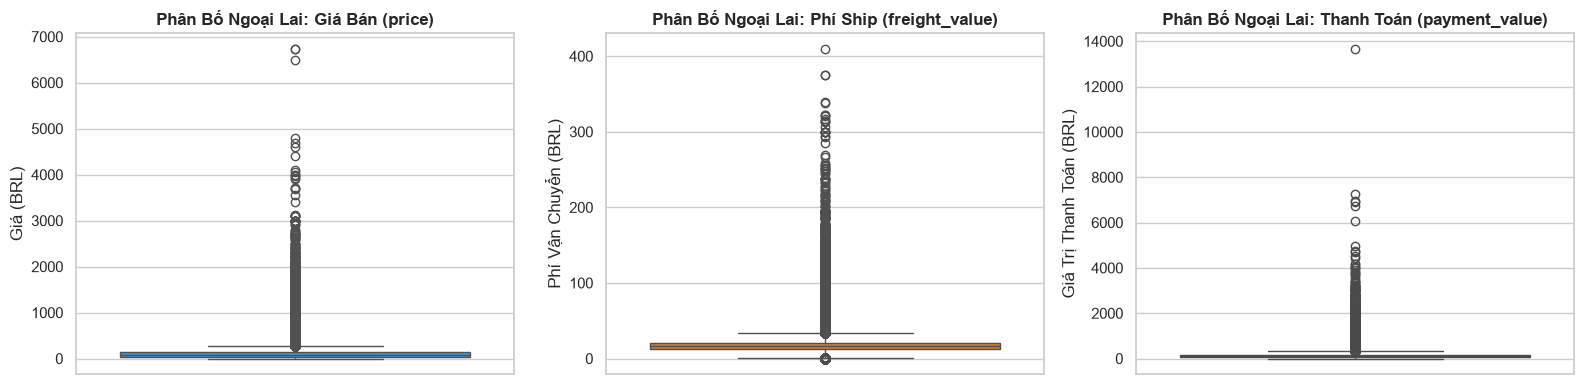

Ngưỡng ngoại lai giá bán (Upper Bound): 275.57 BRL
Số dòng được gắn cờ is_price_outlier (Bảo toàn giá): 8,161 dòng (7.41%)
Bảng geolocation sạch sau khi khử ngoại lai và gộp mean: 19,010 mã bưu chính duy nhất.


In [20]:
# 1. Trực quan hóa ngoại lai bằng biểu đồ Boxplots
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.boxplot(y=dfs['order_items']['price'], ax=axes[0], color='#3498db')
axes[0].set_title('Phân Bố Ngoại Lai: Giá Bán (price)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Giá (BRL)')

sns.boxplot(y=dfs['order_items']['freight_value'], ax=axes[1], color='#e67e22')
axes[1].set_title('Phân Bố Ngoại Lai: Phí Ship (freight_value)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Phí Vận Chuyển (BRL)')

sns.boxplot(y=dfs['payments']['payment_value'], ax=axes[2], color='#2ecc71')
axes[2].set_title('Phân Bố Ngoại Lai: Thanh Toán (payment_value)', fontsize=12, fontweight='bold')
axes[2].set_ylabel('Giá Trị Thanh Toán (BRL)')

plt.tight_layout()
plt.show()

# 2. Tính toán khung toán học IQR cho đơn giá (price)
q1_price = dfs['order_items']['price'].quantile(0.25)
q3_price = dfs['order_items']['price'].quantile(0.75)
iqr_price = q3_price - q1_price
price_upper_bound = q3_price + 1.5 * iqr_price

# Chiến lược Preservation: Gắn cờ ngoại lai nhị phân, bảo toàn doanh số
dfs['order_items']['is_price_outlier'] = (dfs['order_items']['price'] > price_upper_bound).astype(int)
dfs['order_items']['item_total_value'] = dfs['order_items']['price'] + dfs['order_items']['freight_value']

print(f"Ngưỡng ngoại lai giá bán (Upper Bound): {price_upper_bound:.2f} BRL")
print(f"Số dòng được gắn cờ is_price_outlier (Bảo toàn giá): {dfs['order_items']['is_price_outlier'].sum():,} dòng ({dfs['order_items']['is_price_outlier'].mean()*100:.2f}%)")

# 3. Chiến lược Removal & Capping trên bảng payments
b_pay = len(dfs['payments'])
dfs['payments'] = dfs['payments'][
    (dfs['payments']['payment_type'] != 'not_defined') &
    (dfs['payments']['payment_value'] > 0)
].copy()
dfs['payments']['payment_installments'] = dfs['payments']['payment_installments'].clip(lower=1)
pipeline_logger.record('Outlier Treatment', 'payments', b_pay, len(dfs['payments']), 
                       'Removal: Xóa payment_value<=0 & not_defined; Capping: Clip số kỳ trả góp >= 1')

# 4. Chiến lược Removal & Tổng hợp trên bảng geolocation
b_geo = len(dfs['geolocation'])
df_geo_valid = dfs['geolocation'][
    dfs['geolocation']['geolocation_lat'].between(*BRAZIL_LAT_BOUNDS) &
    dfs['geolocation']['geolocation_lng'].between(*BRAZIL_LNG_BOUNDS)
].copy()

dfs['geolocation'] = (
    df_geo_valid
    .groupby('geolocation_zip_code_prefix', as_index=False)
    .agg({
        'geolocation_lat': 'mean',
        'geolocation_lng': 'mean',
        'geolocation_city': 'first',
        'geolocation_state': 'first'
    })
)
pipeline_logger.record('Outlier Treatment', 'geolocation', b_geo, len(dfs['geolocation']), 
                       'Removal & Aggregation: Lọc tọa độ ngoài Brazil, gộp mean(lat, lng) 1 dòng/zip code')

print(f"Bảng geolocation sạch sau khi khử ngoại lai và gộp mean: {len(dfs['geolocation']):,} mã bưu chính duy nhất.")


## 4. Feature Engineering & Categorical Encoding (Kỹ Thuật Đặc Trưng & Mã Hóa Biến)
Giai đoạn xây dựng đặc trưng trích xuất các biến dự báo quan trọng cho bài toán phân tích hành vi và dự báo điểm đánh giá (`review_score`):
- **Trích xuất đặc trưng mới từ thuộc tính gốc (Detail logic for newly engineered features):**
  - Nhóm Thời gian: `delivery_duration` (`delivery_days`), `estimated_duration` (`estimated_days`), `delay_days`, `is_delayed`, `purchase_year`, `purchase_month`, `purchase_weekday`, `purchase_hour`.
  - Nhóm Tài chính & Giỏ hàng: `total_order_price`, `total_freight_value`, `total_order_value`, `freight_ratio`, `total_items_count`, `has_price_outlier`.
  - Nhóm Giao dịch & Địa lý: `main_payment_type`, `max_installments`, `has_review_comment`, `same_state`, `product_volume_cm3`.
- **Mã hóa biến phân loại (Transform categorical factors into numeric designations):**
  - One-Hot Encoding cho `main_payment_type` (`credit_card`, `boleto`, `voucher`, `debit_card`).
  - One-Hot Encoding cho `customer_state`: Lấy Top 5 bang có lượng giao dịch lớn nhất (`SP`, `RJ`, `MG`, `RS`, `PR`) và nhóm còn lại thành `Other` để chống bùng nổ số chiều.
  - Xây dựng bảng dữ liệu hoàn chỉnh ở **mức đơn hàng (`df_orders_ml`: 1 dòng = 1 đơn hàng)** sẵn sàng 100% cho các thuật toán Machine Learning.


In [21]:
# 1. Trích xuất các đặc trưng thời gian trên bảng orders
purchase_ts = dfs['orders']['order_purchase_timestamp']
delivery_ts = dfs['orders']['order_delivered_customer_date']
estimated_ts = dfs['orders']['order_estimated_delivery_date']

dfs['orders']['delivery_duration'] = ((delivery_ts - purchase_ts).dt.total_seconds() / 86400).round(2)
dfs['orders']['delivery_days'] = dfs['orders']['delivery_duration'] # Tương thích tên gọi
dfs['orders']['estimated_duration'] = ((estimated_ts - purchase_ts).dt.total_seconds() / 86400).round(2)
dfs['orders']['delay_days'] = ((delivery_ts.dt.normalize() - estimated_ts.dt.normalize()).dt.total_seconds() / 86400).round(2)
dfs['orders']['is_delayed'] = (dfs['orders']['delay_days'] > 0).astype(int)

dfs['orders']['purchase_year'] = purchase_ts.dt.year
dfs['orders']['purchase_month'] = purchase_ts.dt.month
dfs['orders']['purchase_year_month'] = purchase_ts.dt.to_period('M').astype(str)
dfs['orders']['purchase_weekday'] = purchase_ts.dt.dayofweek
dfs['orders']['purchase_hour'] = purchase_ts.dt.hour

# 2. Trích xuất đặc trưng thể tích đóng gói trên bảng products
dfs['products']['product_volume_cm3'] = (
    dfs['products']['product_length_cm'] *
    dfs['products']['product_height_cm'] *
    dfs['products']['product_width_cm']
).round(2)

# 3. Tổng hợp chỉ số tài chính & giỏ hàng từ order_items theo từng đơn hàng
items_order_agg = dfs['order_items'].groupby('order_id').agg(
    total_order_price=('price', 'sum'),
    total_freight_value=('freight_value', 'sum'),
    total_items_count=('order_item_id', 'count'),
    has_price_outlier=('is_price_outlier', 'max')
).reset_index()

items_order_agg['total_order_value'] = items_order_agg['total_order_price'] + items_order_agg['total_freight_value']
items_order_agg['freight_ratio'] = (items_order_agg['total_freight_value'] / items_order_agg['total_order_value']).round(4)

# 4. Xác định phương thức thanh toán chủ đạo và tổng hợp số kỳ trả góp từ payments
main_payment = (
    dfs['payments']
    .sort_values(by='payment_value', ascending=False)
    .drop_duplicates(subset=['order_id'], keep='first')[['order_id', 'payment_type']]
    .rename(columns={'payment_type': 'main_payment_type'})
)

payment_order_agg = dfs['payments'].groupby('order_id').agg(
    total_payment_value=('payment_value', 'sum'),
    max_installments=('payment_installments', 'max'),
    payment_transactions_count=('payment_sequential', 'count')
).reset_index().merge(main_payment, on='order_id', how='left')

# 5. Dựng bảng dữ liệu phân tích mức đơn hàng (Order-level dataset cho Machine Learning)
df_orders_ml = (
    dfs['orders']
    .merge(items_order_agg, on='order_id', how='inner')
    .merge(payment_order_agg, on='order_id', how='inner')
    .merge(dfs['customers'][['customer_id', 'customer_unique_id', 'customer_state', 'customer_zip_code_prefix']], on='customer_id', how='left')
    .merge(dfs['reviews'][['order_id', 'review_score', 'has_review_comment']], on='order_id', how='left')
)

# 6. Mã hóa biến phân loại (Categorical Encoding) sang dạng số
encoded_payment_dummies = pd.get_dummies(df_orders_ml['main_payment_type'], prefix='pay', drop_first=True, dtype=int)

top_states = df_orders_ml['customer_state'].value_counts().nlargest(5).index
df_orders_ml['state_grouped'] = df_orders_ml['customer_state'].apply(lambda x: x if x in top_states else 'Other')
encoded_state_dummies = pd.get_dummies(df_orders_ml['state_grouped'], prefix='state', drop_first=True, dtype=int)

df_orders_ml = pd.concat([df_orders_ml, encoded_payment_dummies, encoded_state_dummies], axis=1)

print(f"Quy mô bảng dataset hoàn chỉnh cho Machine Learning (df_orders_ml): {df_orders_ml.shape[0]:,} dòng x {df_orders_ml.shape[1]} cột.")


Quy mô bảng dataset hoàn chỉnh cho Machine Learning (df_orders_ml): 96,469 dòng x 42 cột.


In [22]:
# 7. Bảng danh mục chi tiết toàn bộ các đặc trưng mới được tạo (Engineered Features Catalog)
engineered_features_catalog = pd.DataFrame([
    {
        'Tên Đặc Trưng': 'delivery_duration (delivery_days)',
        'Thuộc Tính Gốc': 'order_delivered_customer_date - order_purchase_timestamp',
        'Kiểu': 'float64',
        'Logic Tính Toán': 'Hiệu số ngày thực tế từ lúc đặt hàng đến khi nhận hàng',
        'Ý Nghĩa Dự Báo': 'Yếu tố ảnh hưởng trực tiếp và mạnh nhất đến điểm review_score'
    },
    {
        'Tên Đặc Trưng': 'estimated_duration',
        'Thuộc Tính Gốc': 'order_estimated_delivery_date - order_purchase_timestamp',
        'Kiểu': 'float64',
        'Logic Tính Toán': 'Khoảng thời gian sàn ước lượng giao hàng lúc khách đặt',
        'Ý Nghĩa Dự Báo': 'Kỳ vọng ban đầu của khách hàng về thời gian nhận hàng'
    },
    {
        'Tên Đặc Trưng': 'delay_days',
        'Thuộc Tính Gốc': 'order_delivered_customer_date - order_estimated_delivery_date',
        'Kiểu': 'float64',
        'Logic Tính Toán': 'Số ngày nhận hàng trễ so với ngày cam kết ban đầu (> 0 là trễ)',
        'Ý Nghĩa Dự Báo': 'Chỉ báo mức độ thất vọng của người mua khi bị trễ hạn'
    },
    {
        'Tên Đặc Trưng': 'is_delayed',
        'Thuộc Tính Gốc': 'delay_days > 0',
        'Kiểu': 'int64 (binary)',
        'Logic Tính Toán': '1 nếu giao trễ hẹn, 0 nếu đúng hẹn hoặc sớm hơn hẹn',
        'Ý Nghĩa Dự Báo': 'Cờ nhị phân phân loại đơn hàng gặp sự cố vận chuyển'
    },
    {
        'Tên Đặc Trưng': 'total_order_price',
        'Thuộc Tính Gốc': 'order_items.price (sum)',
        'Kiểu': 'float64',
        'Logic Tính Toán': 'Tổng tiền hàng của tất cả sản phẩm trong đơn',
        'Ý Nghĩa Dự Báo': 'Quy mô chi tiêu tiền hàng của người mua'
    },
    {
        'Tên Đặc Trưng': 'total_freight_value',
        'Thuộc Tính Gốc': 'order_items.freight_value (sum)',
        'Kiểu': 'float64',
        'Logic Tính Toán': 'Tổng phí giao hàng của đơn',
        'Ý Nghĩa Dự Báo': 'Gánh nặng chi phí vận chuyển'
    },
    {
        'Tên Đặc Trưng': 'total_order_value',
        'Thuộc Tính Gốc': 'total_order_price + total_freight_value',
        'Kiểu': 'float64',
        'Logic Tính Toán': 'Tổng giá trị hóa đơn thực tế của đơn hàng',
        'Ý Nghĩa Dự Báo': 'Giá trị đơn hàng (AOV) đo lường phân khúc khách hàng'
    },
    {
        'Tên Đặc Trưng': 'freight_ratio',
        'Thuộc Tính Gốc': 'total_freight_value / total_order_value',
        'Kiểu': 'float64',
        'Logic Tính Toán': 'Tỷ lệ % phí vận chuyển trên tổng hóa đơn',
        'Ý Nghĩa Dự Báo': 'Tỷ lệ phí ship cao thường gây bức xúc và làm giảm điểm đánh giá'
    },
    {
        'Tên Đặc Trưng': 'total_items_count',
        'Thuộc Tính Gốc': 'order_items.order_item_id (count)',
        'Kiểu': 'int64',
        'Logic Tính Toán': 'Số lượng sản phẩm trong một đơn hàng',
        'Ý Nghĩa Dự Báo': 'Đơn hàng nhiều món có rủi ro đóng gói thiếu/sót cao hơn'
    },
    {
        'Tên Đặc Trưng': 'has_price_outlier',
        'Thuộc Tính Gốc': 'order_items.is_price_outlier (max)',
        'Kiểu': 'int64 (binary)',
        'Logic Tính Toán': '1 nếu đơn chứa sản phẩm giá cao bất thường (> 275.57 BRL)',
        'Ý Nghĩa Dự Báo': 'Nhận diện các đơn hàng phân khúc cao cấp'
    },
    {
        'Tên Đặc Trưng': 'main_payment_type',
        'Thuộc Tính Gốc': 'payments.payment_type (max value)',
        'Kiểu': 'category',
        'Logic Tính Toán': 'Phương thức thanh toán chiếm số tiền lớn nhất trong đơn',
        'Ý Nghĩa Dự Báo': 'Hành vi thanh toán của khách (thẻ tín dụng, boleto, voucher)'
    },
    {
        'Tên Đặc Trưng': 'max_installments',
        'Thuộc Tính Gốc': 'payments.payment_installments (max)',
        'Kiểu': 'int64',
        'Logic Tính Toán': 'Số kỳ trả góp dài nhất của đơn hàng',
        'Ý Nghĩa Dự Báo': 'Độ nhạy cảm tài chính của khách hàng'
    },
    {
        'Tên Đặc Trưng': 'has_review_comment',
        'Thuộc Tính Gốc': 'reviews.review_comment_message.notna()',
        'Kiểu': 'int64 (binary)',
        'Logic Tính Toán': '1 nếu khách có viết lời nhận xét, 0 nếu chỉ chấm điểm sao',
        'Ý Nghĩa Dự Báo': 'Mức độ tương tác và cảm xúc (khách rất giận hoặc rất thích)'
    },
    {
        'Tên Đặc Trưng': 'product_volume_cm3',
        'Thuộc Tính Gốc': 'length * height * width (products)',
        'Kiểu': 'float64',
        'Logic Tính Toán': 'Thể tích đóng gói sản phẩm tính theo cm khối',
        'Ý Nghĩa Dự Báo': 'Hàng cồng kềnh dễ va đập hỏng hóc trong vận chuyển'
    },
    {
        'Tên Đặc Trưng': 'pay_* / state_*',
        'Thuộc Tính Gốc': 'main_payment_type / customer_state (One-Hot)',
        'Kiểu': 'int64 (dummy)',
        'Logic Tính Toán': 'Mã hóa One-Hot Encoding cho các biến phân loại',
        'Ý Nghĩa Dự Báo': 'Tương thích trực tiếp với các mô hình Machine Learning downstream'
    }
])

display(engineered_features_catalog)


,Tên Đặc Trưng,Thuộc Tính Gốc,Kiểu,Logic Tính Toán,Ý Nghĩa Dự Báo
0,delivery_duration (delivery_days),order_delivered_customer_date - order_purchase...,float64,Hiệu số ngày thực tế từ lúc đặt hàng đến khi n...,Yếu tố ảnh hưởng trực tiếp và mạnh nhất đến đi...
1,estimated_duration,order_estimated_delivery_date - order_purchase...,float64,Khoảng thời gian sàn ước lượng giao hàng lúc k...,Kỳ vọng ban đầu của khách hàng về thời gian nh...
2,delay_days,order_delivered_customer_date - order_estimate...,float64,Số ngày nhận hàng trễ so với ngày cam kết ban ...,Chỉ báo mức độ thất vọng của người mua khi bị ...
3,is_delayed,delay_days > 0,int64 (binary),"1 nếu giao trễ hẹn, 0 nếu đúng hẹn hoặc sớm hơ...",Cờ nhị phân phân loại đơn hàng gặp sự cố vận c...
4,total_order_price,order_items.price (sum),float64,Tổng tiền hàng của tất cả sản phẩm trong đơn,Quy mô chi tiêu tiền hàng của người mua
5,total_freight_value,order_items.freight_value (sum),float64,Tổng phí giao hàng của đơn,Gánh nặng chi phí vận chuyển
6,total_order_value,total_order_price + total_freight_value,float64,Tổng giá trị hóa đơn thực tế của đơn hàng,Giá trị đơn hàng (AOV) đo lường phân khúc khác...
7,freight_ratio,total_freight_value / total_order_value,float64,Tỷ lệ % phí vận chuyển trên tổng hóa đơn,Tỷ lệ phí ship cao thường gây bức xúc và làm g...
8,total_items_count,order_items.order_item_id (count),int64,Số lượng sản phẩm trong một đơn hàng,Đơn hàng nhiều món có rủi ro đóng gói thiếu/só...
9,has_price_outlier,order_items.is_price_outlier (max),int64 (binary),1 nếu đơn chứa sản phẩm giá cao bất thường (> ...,Nhận diện các đơn hàng phân khúc cao cấp


## 5. Kiểm Chứng Chất Lượng Toàn Diện & Xuất Dữ Liệu Sạch (Validation Audit & Export)
- Chạy lại bộ kiểm tra toàn vẹn **14 tiêu chuẩn kỹ thuật** để đảm bảo không còn bất kỳ vi phạm nào về khóa, missing hay kiểu dữ liệu.
- Trình bày **Bảng nhật ký biến động số dòng (Preprocessing Logger)** ghi vết từng quyết định xử lý.
- Xuất 9 bảng dữ liệu sạch và 2 bảng dữ liệu phân tích (`olist_master.csv`, `olist_orders_ml.csv`) sang thư mục `data/processed/`.


In [23]:
# 1. Dựng bảng tổng hợp đa bảng mức mặt hàng (df_master_clean) để kiểm tra toàn vẹn
df_master_clean = (
    dfs['order_items']
    .merge(dfs['orders'], on='order_id', how='inner')
    .merge(dfs['products'], on='product_id', how='left')
    .merge(dfs['category_translation'], on='product_category_name', how='left')
    .merge(dfs['customers'], on='customer_id', how='left')
    .merge(dfs['sellers'], on='seller_id', how='left')
    .merge(dfs['reviews'][['order_id', 'review_score', 'has_review_comment']], on='order_id', how='left')
    .merge(payment_order_agg, on='order_id', how='left')
)
df_master_clean['same_state'] = (df_master_clean['customer_state'] == df_master_clean['seller_state']).astype(int)

# 2. Bộ 14 tiêu chuẩn kiểm chứng toàn vẹn
validation_audit = {
    '1. Khóa chính orders.order_id duy nhất': dfs['orders']['order_id'].is_unique,
    '2. Khóa chính reviews: đúng 1 review duy nhất/đơn': dfs['reviews']['order_id'].is_unique,
    '3. Khóa ngoại order_items.order_id hợp lệ 100%': dfs['order_items']['order_id'].isin(dfs['orders']['order_id']).all(),
    '4. Khóa ngoại payments.order_id hợp lệ 100%': dfs['payments']['order_id'].isin(dfs['orders']['order_id']).all(),
    '5. Khóa ngoại order_items.product_id hợp lệ 100%': dfs['order_items']['product_id'].isin(dfs['products']['product_id']).all(),
    '6. Khóa ngoại order_items.seller_id hợp lệ 100%': dfs['order_items']['seller_id'].isin(dfs['sellers']['seller_id']).all(),
    '7. Khóa ngoại orders.customer_id hợp lệ 100%': dfs['orders']['customer_id'].isin(dfs['customers']['customer_id']).all(),
    '8. Bảng products không còn giá trị khuyết thiếu': dfs['products'].isna().sum().sum() == 0,
    '9. 100% danh mục sản phẩm đều có bản dịch tiếng Anh': dfs['products']['product_category_name'].isin(dfs['category_translation']['product_category_name']).all(),
    '10. Bảng geolocation: mỗi mã zip đại diện đúng 1 dòng': dfs['geolocation']['geolocation_zip_code_prefix'].is_unique,
    '11. Toàn bộ mã bưu chính zip code đủ chuẩn 5 ký tự': dfs['customers']['customer_zip_code_prefix'].str.len().eq(5).all(),
    '12. Giá bán và phí vận chuyển đều >= 0': (dfs['order_items'][['price', 'freight_value']] >= 0).all().all(),
    '13. Thời gian giao hàng thực tế delivery_days >= 0': (dfs['orders']['delivery_days'] >= 0).all(),
    '14. Số dòng bảng master khớp chính xác với order_items': len(df_master_clean) == len(dfs['order_items'])
}

df_validation_results = pd.DataFrame(list(validation_audit.items()), columns=['Tiêu Chuẩn Kiểm Thẩm Kỹ Thuật', 'Kết Quả Đạt'])
display(df_validation_results)
assert df_validation_results['Kết Quả Đạt'].all(), "CẢNH BÁO: Còn tiêu chuẩn chưa đạt trong dữ liệu sạch!"
print("TẤT CẢ 14 TIÊU CHUẨN KIỂM CHỨNG TOÀN VẸN ĐỀU ĐẠT 100%!")


,Tiêu Chuẩn Kiểm Thẩm Kỹ Thuật,Kết Quả Đạt
0,1. Khóa chính orders.order_id duy nhất,True
1,2. Khóa chính reviews: đúng 1 review duy nhất/đơn,True
2,3. Khóa ngoại order_items.order_id hợp lệ 100%,True
3,4. Khóa ngoại payments.order_id hợp lệ 100%,True
4,5. Khóa ngoại order_items.product_id hợp lệ 100%,True
5,6. Khóa ngoại order_items.seller_id hợp lệ 100%,True
6,7. Khóa ngoại orders.customer_id hợp lệ 100%,True
7,8. Bảng products không còn giá trị khuyết thiếu,True
8,9. 100% danh mục sản phẩm đều có bản dịch tiến...,True
9,10. Bảng geolocation: mỗi mã zip đại diện đúng...,True


TẤT CẢ 14 TIÊU CHUẨN KIỂM CHỨNG TOÀN VẸN ĐỀU ĐẠT 100%!


In [24]:
# 3. Hiển thị bảng nhật ký biến động số dòng xuyên suốt pipeline
print("--- NHẬT KÝ CHI TIẾT CÁC BƯỚC BIẾN ĐỔI DỮ LIỆU ---")
display(pipeline_logger.get_dataframe())


--- NHẬT KÝ CHI TIẾT CÁC BƯỚC BIẾN ĐỔI DỮ LIỆU ---


,Giai Đoạn,Bảng Dữ Liệu,Số Dòng Trước,Số Dòng Sau,Số Dòng Giảm,Tỷ Lệ Giữ Lại (%),Chiến Lược & Ghi Chú
0,Handling Missing Values,orders,"99,441","96,469","2,972",97.01%,"Row Deletion: Giữ đơn delivered hợp lệ, loại 8..."
1,Handling Missing Values,order_items,"112,650","110,186","2,464",97.81%,Đồng bộ khóa ngoại theo tập orders sạch
2,Handling Missing Values,payments,"103,886","100,748","3,138",96.98%,Đồng bộ khóa ngoại theo tập orders sạch
3,Handling Missing Values,reviews,"99,224","96,352","2,872",97.11%,Đồng bộ khóa ngoại theo tập orders sạch
4,Handling Missing Values,customers,"99,441","96,469","2,972",97.01%,Đồng bộ customer_id
5,Handling Missing Values,products,"32,951","32,214",737,97.76%,Đồng bộ product_id
6,Handling Missing Values,sellers,"3,095","2,970",125,95.96%,Đồng bộ seller_id
7,Handling Missing Values & Deduplication,reviews,"96,352","95,823",529,99.45%,Giữ 1 review mới nhất/đơn
8,Outlier Treatment,payments,"100,748","100,744",4,100.00%,Removal: Xóa payment_value<=0 & not_defined; C...
9,Outlier Treatment,geolocation,"1,000,163","19,010","981,153",1.90%,Removal & Aggregation: Lọc tọa độ ngoài Brazil...


In [ ]:
# 4. Xuất 9 bảng dữ liệu sạch và 2 bảng phân tích tổng hợp ra thư mục data/processed/
export_mapping = {
    'olist_orders_cleaned.csv': dfs['orders'],
    'olist_order_items_cleaned.csv': dfs['order_items'],
    'olist_order_payments_cleaned.csv': dfs['payments'],
    'olist_order_reviews_cleaned.csv': dfs['reviews'],
    'olist_products_cleaned.csv': dfs['products'],
    'olist_customers_cleaned.csv': dfs['customers'],
    'olist_sellers_cleaned.csv': dfs['sellers'],
    'olist_geolocation_cleaned.csv': dfs['geolocation'],
    'product_category_name_translation_cleaned.csv': dfs['category_translation'],
    'olist_master.csv': df_master_clean,
    'olist_orders_ml.csv': df_orders_ml
}

for filename, df_out in export_mapping.items():
    target_path = PROCESSED_DATA_DIR / filename
    df_out.to_csv(target_path, index=False)
    print(f"Đã xuất: {filename} ({len(df_out):,} dòng x {df_out.shape[1]} cột)")

print(f"\nHOÀN TẤT TOÀN BỘ QUY TRÌNH TIỀN XỬ LÝ! Dữ liệu đã lưu tại: {PROCESSED_DATA_DIR}")


Đã xuất: olist_orders_cleaned.csv (96,469 dòng x 18 cột)
Đã xuất: olist_order_items_cleaned.csv (110,186 dòng x 9 cột)
Đã xuất: olist_order_payments_cleaned.csv (100,744 dòng x 5 cột)
Đã xuất: olist_order_reviews_cleaned.csv (95,823 dòng x 8 cột)
Đã xuất: olist_products_cleaned.csv (32,214 dòng x 10 cột)
Đã xuất: olist_customers_cleaned.csv (96,469 dòng x 5 cột)
Đã xuất: olist_sellers_cleaned.csv (2,970 dòng x 4 cột)
Đã xuất: olist_geolocation_cleaned.csv (19,010 dòng x 5 cột)
Đã xuất: product_category_name_translation_cleaned.csv (74 dòng x 2 cột)
Đã xuất: olist_master.csv (110,186 dòng x 50 cột)
Đã xuất: olist_orders_ml.csv (96,469 dòng x 42 cột)

HOÀN TẤT TOÀN BỘ QUY TRÌNH TIỀN XỬ LÝ! Dữ liệu đã lưu tại: C:\ADY291c-AI2107-Group2\data\processed
